# Handwritten Digit Recognition (MNIST)

Train classical ML models and a CNN on MNIST, then test them on **my own handwritten digits**.

1. Classical models: Logistic Regression, Naive Bayes, Decision Tree, XGBoost
2. CNN with data augmentation
3. Evaluation on 101 new handwritten images

## 1. Setup

In [9]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
# Paths are relative to the notebooks/ folder.
# Download MNIST PNG and put it into data/mnist_png/ (see README).
DATA_DIR = os.path.join("..", "data")
TRAIN_DIR = os.path.join(DATA_DIR, "mnist_png", "train")
TEST_DIR = os.path.join(DATA_DIR, "mnist_png", "test")
NEW_DATA_DIR = os.path.join(DATA_DIR, "handwritten_digits")

IMG_SIZE = (28, 28)
RANDOM_STATE = 42

## 2. Classical ML models

Each image → 28×28 grayscale → flattened to 784 features.

In [11]:
# image preprocessing
def preprocess_image(path):
    img = Image.open(path).convert("L").resize(IMG_SIZE)

    arr = 255 - np.array(img, dtype=np.float32)
    arr /= 255.0

    return arr.flatten()

In [61]:
# data loading
def load_folder_dataset(root_dir):
    X, y, paths = [], [], []

    for label in sorted(os.listdir(root_dir)):
        if not os.path.isdir(os.path.join(root_dir, label)):
            continue

        for fname in os.listdir(os.path.join(root_dir, label)):
            fpath = os.path.join(root_dir, label, fname)

            try:
                X.append(preprocess_image(fpath))
                y.append(int(label))
                paths.append(fpath)
            except Exception as e:
                print(f"Skipping {fpath}: {e}")

    return np.array(X, dtype=np.float32), np.array(y), paths

In [15]:
def get_models():
    return {
        'Logistic Regression': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=1000, solver='lbfgs', multi_class='auto'))
        ]),

        'Naive Bayes': GaussianNB(),

        'Decision Tree': DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),

        'XGBoost': XGBClassifier(
            objective='multi:softmax',
            num_class=10,
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.9,
            colsample_bytree=0.9,
            eval_metric='mlogloss',
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }

In [17]:
# evaluation
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "predictions": y_pred
    }

### Train and evaluate on the MNIST test set

In [21]:
def run_classical_models():
    print("Loading MNIST PNG training data")
    X_train, y_train, _ = load_folder_dataset(TRAIN_DIR)
    print(f"Training samples: {len(X_train)}")

    print("Loading MNIST PNG test data")
    X_test, y_test, _ = load_folder_dataset(TEST_DIR)
    print(f"Test samples: {len(X_test)}")

    models = get_models()

    print("\nTraining and evaluating models...")

    for name, model in models.items():
        print(f"\n{name}")

        current_model = clone(model)
        current_model.fit(X_train, y_train)

        metrics = evaluate_model(current_model, X_test, y_test)

        print(f"Accuracy : {metrics['accuracy']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall   : {metrics['recall']:.4f}")
        print(f"F1-score : {metrics['f1_score']:.4f}")


run_classical_models()

Loading MNIST PNG training data
Training samples: 60000
Loading MNIST PNG test data
Test samples: 10000

Training and evaluating models...

Logistic Regression
Accuracy : 0.9216
Precision: 0.9215
Recall   : 0.9216
F1-score : 0.9215

Naive Bayes
Accuracy : 0.5558
Precision: 0.6917
Recall   : 0.5558
F1-score : 0.5170

Decision Tree
Accuracy : 0.8770
Precision: 0.8768
Recall   : 0.8770
F1-score : 0.8769

XGBoost
Accuracy : 0.9558
Precision: 0.9559
Recall   : 0.9558
F1-score : 0.9558


### Best classical model (XGBoost) on my handwritten digits

In [51]:
def evaluate_new_handwritten_data(model, new_data_dir):

    X_new, y_new, _ = load_folder_dataset(new_data_dir)

    metrics = evaluate_model(model, X_new, y_new)

    print("\n Results on handwritten images")
    print(f"Accuracy : {metrics['accuracy']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"Recall   : {metrics['recall']:.4f}")
    print(f"F1-score : {metrics['f1_score']:.4f}")
    

In [57]:
X_train, y_train, _ = load_folder_dataset(TRAIN_DIR)

xgb_model = get_models()["XGBoost"]

xgb_model.fit(X_train, y_train)

evaluate_new_handwritten_data(xgb_model, NEW_DATA_DIR)


 Results on handwritten images
Accuracy : 0.0200
Precision: 0.0074
Recall   : 0.0200
F1-score : 0.0106


## 3. Convolutional Neural Network

In [63]:
from sklearn.utils import shuffle
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### Preprocessing

MNIST has a white digit on a black background. My photos have a dark digit on a white background, so they are inverted.

In [65]:
def preprocess_mnist_image(image_path):
    img = Image.open(image_path).convert("L")
    img = img.resize(IMG_SIZE)
    arr = np.array(img).astype("float32") / 255.0
    return arr


def preprocess_handwritten_image(image_path):
    img = Image.open(image_path).convert("L")
    img = img.resize(IMG_SIZE)

    arr = np.array(img).astype("float32")
    arr = 255.0 - arr   # black digit on white background -> white digit on dark background
    arr = arr / 255.0

    return arr

In [85]:
def load_dataset(root_dir, handwritten=False):
    X, y = [], []

    valid_extensions = (".png", ".jpg", ".jpeg", ".bmp")

    for label in sorted(os.listdir(root_dir)):
        label_path = os.path.join(root_dir, label)

        if not os.path.isdir(label_path):
            continue

        for fname in os.listdir(label_path):

            # skip non-image files like desktop.ini
            if not fname.lower().endswith(valid_extensions):
                continue

            fpath = os.path.join(label_path, fname)

            if handwritten:
                img = preprocess_handwritten_image(fpath)
            else:
                img = preprocess_mnist_image(fpath)

            X.append(img)
            y.append(int(label))

    X = np.array(X).reshape(-1, 28, 28, 1)
    y = np.array(y)

    return X, y

### Model

In [69]:
def build_cnn():
    model = Sequential([
        Input(shape=(28, 28, 1)),

        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.4),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [71]:
def print_metrics(title, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )

    print(f"\n{title}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

In [73]:
# load and prepare MNIST data
print("Loading training data")
X_train, y_train = load_dataset(TRAIN_DIR, handwritten=False)

print("Loading test data")
X_test, y_test = load_dataset(TEST_DIR, handwritten=False)

X_train, y_train = shuffle(X_train, y_train, random_state=42)

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

Loading training data
Loading test data


In [75]:
# build model
model = build_cnn()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

### Data augmentation

Small random rotations, shifts and zoom make the model more robust to real handwriting.

In [77]:
# data augmentation
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10
)

datagen.fit(X_train)

### Training

In [79]:
# train the model
model.fit(
    datagen.flow(X_train, y_train_cat, batch_size=128),
    epochs=15,
    validation_data=(X_test, y_test_cat),
    callbacks=[early_stop],
    verbose=1
)
# evaluate on mnist dataset
y_test_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print_metrics("CNN results on MNIST test data", y_test, y_test_pred)

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.8518 - loss: 0.4725 - val_accuracy: 0.9788 - val_loss: 0.0632
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.9490 - loss: 0.1685 - val_accuracy: 0.9875 - val_loss: 0.0351
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9611 - loss: 0.1313 - val_accuracy: 0.9884 - val_loss: 0.0350
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9674 - loss: 0.1090 - val_accuracy: 0.9871 - val_loss: 0.0350
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9719 - loss: 0.0947 - val_accuracy: 0.9907 - val_loss: 0.0263
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 34ms/step - accuracy: 0.9742 - loss: 0.0865 - val_accuracy: 0.9918 - val_loss: 0.0236
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9766 - loss: 0.0781 - val_accuracy: 0.9918 - val_loss: 0.0251
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.9796 - loss: 0.0703 - 

## 4. CNN on my handwritten digits

In [87]:
# load handwritten images and evaluate
X_new, y_new = load_dataset(NEW_DATA_DIR, handwritten=True)

y_new_pred = np.argmax(model.predict(X_new, verbose=0), axis=1)

print_metrics("CNN results on new handwritten images", y_new, y_new_pred)


CNN results on new handwritten images
Accuracy : 0.7921
Precision: 0.8148
Recall   : 0.7921
F1-score : 0.7801


In [89]:
results_df = pd.DataFrame({
    "True_Label": y_new,
    "Predicted_Label": y_new_pred
})

output_file = "cnn_handwritten_predictions.csv"
results_df.to_csv(output_file, index=False)

print(f"Predictions saved to {output_file}")

Predictions saved to cnn_handwritten_predictions.csv


## 5. Augmentation examples

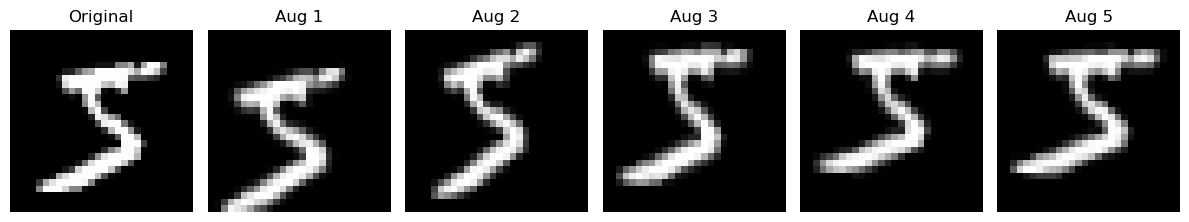

In [95]:
import matplotlib.pyplot as plt
img_path = os.path.join(TRAIN_DIR, "5", "0.png")

# load and preprocess
img = preprocess_mnist_image(img_path)           # shape: (28, 28)
img = img.reshape((1, 28, 28, 1))               # batch shape for ImageDataGenerator

# same augmentation settings as training
preview_datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10
)

plt.figure(figsize=(12, 3))

plt.subplot(1, 6, 1)
plt.imshow(img[0].reshape(28, 28), cmap="gray")
plt.title("Original")
plt.axis("off")

aug_iter = preview_datagen.flow(img, batch_size=1)

for i in range(5):
    aug_img = next(aug_iter)[0].reshape(28, 28)
    plt.subplot(1, 6, i + 2)
    plt.imshow(aug_img, cmap="gray")
    plt.title(f"Aug {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()